# Project 2 — Cloud Image Dataset Construction and Scraping
**MSDS 565 | TeamKAI — KeiTonia, Ashley, India**  
**Notebook 1 of 4 | CRISP-DM: Data Understanding and Collection**

**Starting point:** the instructor-provided `ddgs_image_scraper.ipynb`, renamed. Its numbered sections and workflow are kept; our team's work is added inside each section under **TeamKAI** headings.

**Objective:** scrape five cloud types, check every download, and export `data/P2_manifest.csv`.

**Copyright and the repo:** scraped images belong to whoever made them. We use them for coursework only. The images are saved in a local folder **outside the repo**; they are never committed, shared, or published. Only the manifest (links and labels) is committed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math

pd.set_option('display.max_columns',100)
pd.set_option('display.max_rows',100)

#plt.style.use('dark_background')

import warnings
warnings.filterwarnings('ignore')

# The scraper lives in ddgs_scraper.py, in this same folder. Keep the two files
# together — if you move this notebook into your repo, move the module with it.
import ddgs_scraper

## 1. What the scraper does

`ddgs_scraper.py` wraps the `ddgs` package, which queries web image search. By default it asks Bing
Images directly — the same index DuckDuckGo Images draws its results from — because that is the
backend that works reliably (see `backend` in section 3). The pieces you will actually call are:

| Function | What it does |
|---|---|
| `search_images(query, ...)` | One search, paged until it has enough results. Returns raw result records — image URL, page URL, title, reported size |
| `download_image(url, ...)` | Fetches one URL and returns an RGB PIL image, or `None` if it isn't one |
| `passes_image_filters(img, ...)` | Checks a downloaded image against size and aspect-ratio limits |
| `scrape_class(label, queries, ...)` | All queries for one class, into one folder |
| `build_image_dataset(class_queries, ...)` | Every class. **This is the one you call.** |

Two things the scraper deliberately does *not* do, because they are your job in Notebook 2:
it does not check for duplicate images, and it does not judge whether the picture is actually of
the thing you searched for.

Read the module before running it. The arguments below are not magic numbers and you will be asked
to defend them.

In [2]:
# The filters every downloaded image has to pass. Both are measured on the image
# that actually arrived, not on the size the search engine claimed.
help(ddgs_scraper.build_image_dataset)

Help on function build_image_dataset in module ddgs_scraper:

build_image_dataset(
    class_queries: dict,
    save_dir: str | pathlib._local.Path,
    images_per_class: int = 250,
    results_per_query: int = 200,
    aspect_ratio_range: tuple = (0.5, 2.0),
    min_resolution: tuple = (200, 200),
    per_image_timeout: int = 10,
    backend: str = 'bing',
    safesearch: str = 'moderate',
    region: str = 'us-en',
    require_query_match: bool = True,
    query_delay: tuple = (2.0, 5.0),
    continue_on_error: bool = True,
    verbose: bool = True
) -> tuple[list[dict], dict]
    Download a labeled image dataset from an image search engine.

    One folder per class is created inside save_dir. Every class may have
    several search queries, and results from all of a class's queries land in
    the same folder — using several queries per class is how you get a class
    that looks like the whole category instead of one narrow slice of it.
    Every query is used: downloads take turn

**In simple terms: what the scraper does**
- `help()` prints the scraper's own instructions, so we know the exact setting names it accepts.
- The scraper searches Bing, downloads each result, skips images that are too small or oddly shaped, and saves the good ones into one folder per class.
- It does **not** remove duplicates or check that a photo shows the right cloud. That is our job in Notebook 2.

## 2. Declaring your classes and queries

### 2.1 Choosing classes

Your categories are your choice, within the constraints in the assignment prompt: 3–10 classes, at
least 200 usable images each *after* cleaning, not a standard benchmark, and visually
distinguishable but not trivially so.

The last one is the constraint people get wrong. Classes a model separates at 99% teach you
nothing, and classes that are genuinely ambiguous teach you nothing either. Aim for categories a
person could sort reliably but not instantly — different hand tools, dog breeds, architectural
styles, cloud types, guitar body shapes.

### 2.2 Why several queries per class

A single search returns a narrow, repetitive slice of a category. Search "hammer" and you get a
thousand near-identical product photos of claw hammers on white backgrounds. Your model will learn
"white background" and fall over on the first photo taken in a garage.

Several queries per class widen what the class looks like, and they are also the main reason a
class survives deduplication with enough images left. The scraper uses every query: it searches
them all, then takes turns between them when downloading — first result of each query, then the
second of each — so each query supplies a roughly equal share of the class. If one query runs dry,
the others make up the difference. The run log reports how many images came from each query;
the `query` column of the manifest records it per image.

### TeamKAI class declaration

**Chosen classes (5): cumulus, stratus, cirrus, cumulonimbus, altocumulus** — cloud types.

| Constraint | How our classes meet it |
|---|---|
| 3–10 classes | 5 classes gives a readable confusion matrix and a scraping workload that fits the time available. |
| ≥ 200 usable images after cleaning | Cloud photos are plentiful and well labeled online. We save up to **400 per class** from 3 queries each, so a class can lose about a third to junk and duplicates and still keep 200+. A class that cannot reach 200 will be replaced, not padded with junk. |
| Not a standard benchmark | This is not MNIST, CIFAR, or cats-vs-dogs. Every image comes from an uncurated web search that no one has cleaned or labeled before us. |
| Visually distinguishable but not trivial | A person can sort them by shape and texture: **puffy** cumulus, **flat gray layers** of stratus, **thin wisps** of cirrus, **towering storm** cumulonimbus, **small patches in rows** of altocumulus. But the lines blur: height is not visible in one photo, and storm skies can look like stratus. |

**Where we expect the model to struggle**
- **cumulus vs. altocumulus:** both are puffy; the main difference is size and height, which a flat photo hides.
- **stratus vs. cumulonimbus:** a dark storm base filling the frame can look like a flat gray layer.

**Where we expect messy search results**
- "low stratus fog clouds sky" will return ground-level fog and misty landscapes.
- "altocumulus" results often include look-alike cirrocumulus.
- Sky photos often include landscapes (beaches, fields), and that background may line up with a class. Notebook 4 will check whether the model is using the background instead of the cloud.

### Prediction (stated before any modeling)
> **We predict the most-confused pair will be `cumulus` ↔ `altocumulus`.** Notebook 3 will check this.

In [3]:
CLASS_QUERIES = {
    "cumulus": ["cumulus clouds", "fair weather cumulus sky", "cumulus humilis clouds"],
    "stratus": ["stratus clouds overcast", "stratus cloud layer sky", "low stratus fog clouds sky"],
    "cirrus": ["cirrus clouds", "wispy cirrus clouds sky", "cirrus fibratus clouds"],
    "cumulonimbus": ["cumulonimbus clouds", "towering cumulonimbus thunderstorm", "cumulonimbus incus cloud"],
    "altocumulus": ["altocumulus clouds", "altocumulus cloud patches sky", "altocumulus stratiformis clouds"],
}

for label, queries in CLASS_QUERIES.items():
    print(f'{label:<20} {len(queries)} queries')

cumulus              3 queries
stratus              3 queries
cirrus               3 queries
cumulonimbus         3 queries
altocumulus          3 queries


**In simple terms: the search phrases**
- `CLASS_QUERIES` lists the exact search phrases for each cloud type. **This is our record of the search terms used.**
- Each class has **3 phrases**: a plain one (e.g. "cumulus clouds"), a scene one (e.g. "fair weather cumulus sky"), and a specific sub-type (e.g. "cumulus humilis clouds"). Different phrases give more variety, so the model sees many kinds of each cloud.
- **Output:** a count showing 3 queries per class.

## 3. Running the scraper

The settings below are small on purpose — this is a demonstration run that should finish in a
minute or two. **For your actual dataset you will need much larger numbers.**

A rough guide: to end up with 200 usable images per class after Notebook 2's cleaning, plan to
save 300–400 per class here. You will lose images to wrong subjects, duplicates, and files that
turn out not to open.

Each argument is a decision you have to justify in your writeup:

- `save_dir` — where the images go: your local class data folder, **never** inside your repo. Only the manifest is committed
- `images_per_class` — how many you keep. Set it above your target, not at it
- `results_per_query` — how many search results to collect, fetched a page at a time. Most will not survive download and filtering
- `min_resolution` — a floor on quality. Small images look terrible resized up to 224×224
- `aspect_ratio_range` — rejects banners and infographics, which are rarely pictures of your subject
- `per_image_timeout` — seconds allowed for one download, start to finish. Each image gets one attempt; a slow or dead host is skipped, not retried
- `backend` — which search engine `ddgs` asks. `'bing'` is the reliable one. DuckDuckGo's image results come from Bing anyway, and the `'duckduckgo'` backend currently fails on every request
- `safesearch` — leave it at `'moderate'`. Note that the `'bing'` backend ignores it and always applies Bing's default, which is Moderate
- `region` — changes what you get back. Say so if you change it. Also ignored by `'bing'`
- `require_query_match` — drops results that never mention your query (section 3.2). Leave it on unless your query's words genuinely do not appear in image titles

### 3.1 Expect to be rate limited

Search engines throttle scrapers, and when they do the `ddgs` package reports **"No results
found"** rather than an explicit rate-limit error. That looks identical to a query that genuinely
matched nothing.

The scraper retries a few times with backoff before believing it, and marks any class that ends
with zero images as `empty` in the summary rather than `ok`. You still need to watch for it:

- A class reported as `empty`, or with far fewer images than its neighbours, is almost always
  throttling — not a bad query
- The fix is to wait several minutes and re-run **just that class**. Images already saved stay put,
  but note that filenames restart at `_0000`, so scrape a class into a clean folder or renumber
- Scraping five classes at full scale in one uninterrupted run is unlikely to work. Plan to do it
  in batches over more than one sitting
- This is the single most common reason a class comes up short of 200. Start early

### 3.2 Watch for results from someone else's search

Occasionally the search engine answers with a page of results for a different query entirely — a
search for "acoustic guitar" once came back as 35 stills from a 1991 movie. Those images download
fine and pass every size filter, so nothing downstream would stop them landing in your class folder.

The scraper checks every page it gets back. A result whose title, page URL, and image URL never
mention a word of your query is dropped, and a page where fewer than half the results mention it is
treated as a bad response and retried, the same way an empty page is.

This is a guard against garbage, **not** a label check: an electric guitar titled "guitar" still
passes a query for "acoustic guitar". Catching those is what section 5 and Notebook 2 are for.

### TeamKAI scraper settings and reasons

The demo values above are replaced with full-scale values in the next cell. Every value in this table is exactly what the code passes.

| Argument | Our value | Why |
|---|---|---|
| `save_dir` | `~/MSDS565_data/P2_images` | A local folder in the home directory, **outside the repo**, so images are never committed. |
| `images_per_class` | **400** | How many images to keep per class. We need 200 after cleaning and expect to lose about a third, so we aim well above 300. |
| `results_per_query` | **200** | How many search results to look through per query (the scraper's default). 3 queries × 200 = up to 600 candidates per class, because many fail to download or fail the filters. |
| `min_resolution` | **(224, 224)** | The models take 224×224 input. Smaller images would be blown up and blurry, and cloud texture is the main signal. |
| `aspect_ratio_range` | **(0.5, 2.0)** | Rejects long banners and tall infographics, which are rarely cloud photos. Sky photos are usually landscape, so we keep the range generous. |
| `per_image_timeout` | **10 s** | Long enough for slow websites, short enough that dead links don't stall the run. Each image gets one try. |
| `backend` | **`'bing'`** | The scraper's default and the one that works reliably. We keep one backend for the whole project so the mix of images stays consistent. |
| `safesearch` | **`'moderate'`** | Weather photos are harmless. The scraper notes that Bing ignores this and always applies Moderate, so we set it only to make that clear. |
| `region` | **`'us-en'`** | Left at the default. Also ignored by Bing. |
| `require_query_match` | **True (kept on)** | Drops results whose title and links never mention the query, and retries pages that are mostly off-topic. It is a cheap filter for garbage, not a label check. |
| `query_delay` | **(2.0, 5.0) s** | A random pause between queries to reduce rate limiting (the default, written out so it is visible). |

**How we handle rate limiting:** full-scale scraping of all five classes in one run is unlikely to work, so the code below scrapes **one class per cell**. If a class comes back `empty` or far short, wait several minutes and re-run **just that cell**. Re-running a class first empties that class's folder, because filenames restart at `_0000` and would otherwise overwrite older images and break the manifest.

In [4]:
from pathlib import Path
import shutil

# Scraped images NEVER go in your repo — only the manifest does. Point this at
# your local class data folder. The default is a folder in your home directory,
# outside any repo.
IMAGE_DIR = Path.home() / 'MSDS565_data' / 'P2_images'

# Full scale: save up to 400 per class so 200 survive Notebook 2's cleaning.
IMAGES_PER_CLASS = 400

SCRAPE_ARGS = dict(
    images_per_class=IMAGES_PER_CLASS,
    results_per_query=200,
    aspect_ratio_range=(0.5, 2.0),
    min_resolution=(224, 224),
    per_image_timeout=10,
    backend='bing',
    safesearch='moderate',
    region='us-en',
    require_query_match=True,
    query_delay=(2.0, 5.0),
)

# Results are collected one class at a time, so a rate-limited class can be re-run alone.
class_records = {}   # label -> list of records for that class
class_info = {}      # label -> that class's entry from the scraper's summary

def scrape(label):
    """Scrape one class with build_image_dataset into a clean folder."""
    folder = IMAGE_DIR / label
    if folder.exists():
        shutil.rmtree(folder)   # filenames restart at _0000, so start clean
    recs, summ = ddgs_scraper.build_image_dataset(
        class_queries={label: CLASS_QUERIES[label]},
        save_dir=IMAGE_DIR,
        **SCRAPE_ARGS,
    )
    class_records[label] = recs
    class_info[label] = summ['classes'][label]
    print(f"\n{label}: {class_info[label]['saved']} saved, status = {class_info[label]['status']}")

**In simple terms: the settings and the helper**
- `SCRAPE_ARGS` holds the rules from the table above. The names match the scraper's `help()` exactly.
- `scrape(label)` downloads one cloud type. It empties that cloud's folder first, so re-running it never mixes old and new pictures.
- **Output:** none. The next cells do the downloading.

**Run the next five cells one at a time.** Each takes several minutes. If one comes back `empty` or far below 400, wait a few minutes and run that one cell again.

In [5]:
scrape("cumulus")


[1/1] class 'cumulus' — 3 queries
  query 1/3: 'cumulus clouds'
    200 results returned
  query 2/3: 'fair weather cumulus sky'
    200 results returned
  query 3/3: 'cumulus humilis clouds'
    200 results returned
  downloading from 600 results, taking turns between queries
    ...tried 10, class has 10/400
    ...tried 20, class has 20/400
    ...tried 30, class has 30/400
    ...tried 40, class has 40/400
    ...tried 50, class has 50/400
    ...tried 60, class has 59/400
    ...tried 70, class has 68/400
    ...tried 80, class has 77/400
    ...tried 90, class has 85/400
    ...tried 100, class has 92/400
    ...tried 110, class has 101/400
    ...tried 120, class has 110/400
    ...tried 130, class has 120/400
    ...tried 140, class has 129/400
    ...tried 150, class has 139/400
    ...tried 160, class has 149/400
    ...tried 170, class has 158/400
    ...tried 180, class has 168/400
    ...tried 190, class has 178/400
    ...tried 200, class has 188/400
    ...tried 210, cl

In [6]:
scrape("stratus")


[1/1] class 'stratus' — 3 queries
  query 1/3: 'stratus clouds overcast'
    200 results returned
  query 2/3: 'stratus cloud layer sky'
    page 5: dropped 1 of 35 results that do not mention the query
    page 7: dropped 1 of 35 results that do not mention the query
    200 results returned
  query 3/3: 'low stratus fog clouds sky'
    page 5: dropped 2 of 35 results that do not mention the query
    page 6: dropped 2 of 35 results that do not mention the query
    200 results returned
  downloading from 600 results, taking turns between queries
    ...tried 10, class has 10/400
    ...tried 20, class has 20/400
    ...tried 30, class has 30/400
    ...tried 40, class has 40/400
    ...tried 50, class has 50/400
    ...tried 60, class has 60/400
    ...tried 70, class has 70/400
    ...tried 80, class has 78/400
    ...tried 90, class has 86/400
    ...tried 100, class has 94/400
    ...tried 110, class has 104/400
    ...tried 120, class has 113/400
    ...tried 130, class has 121/

In [7]:
scrape("cirrus")


[1/1] class 'cirrus' — 3 queries
  query 1/3: 'cirrus clouds'
    page 5: dropped 1 of 35 results that do not mention the query
    200 results returned
  query 2/3: 'wispy cirrus clouds sky'
    200 results returned
  query 3/3: 'cirrus fibratus clouds'
    200 results returned
  downloading from 600 results, taking turns between queries
    ...tried 10, class has 7/400
    ...tried 20, class has 17/400
    ...tried 30, class has 27/400
    ...tried 40, class has 37/400
    ...tried 50, class has 47/400
    ...tried 60, class has 57/400
    ...tried 70, class has 67/400
    ...tried 80, class has 77/400
    ...tried 90, class has 87/400
    ...tried 100, class has 96/400
    ...tried 110, class has 106/400
    ...tried 120, class has 116/400
    ...tried 130, class has 126/400
    ...tried 140, class has 136/400
    ...tried 150, class has 146/400
    ...tried 160, class has 156/400
    ...tried 170, class has 165/400
    ...tried 180, class has 174/400
    ...tried 190, class has 18

In [8]:
scrape("cumulonimbus")


[1/1] class 'cumulonimbus' — 3 queries
  query 1/3: 'cumulonimbus clouds'
    page 4: dropped 1 of 35 results that do not mention the query
    200 results returned
  query 2/3: 'towering cumulonimbus thunderstorm'
    page 1: dropped 2 of 35 results that do not mention the query
    page 4: dropped 1 of 35 results that do not mention the query
    page 7: dropped 2 of 35 results that do not mention the query
    200 results returned
  query 3/3: 'cumulonimbus incus cloud'
    page 4: dropped 1 of 35 results that do not mention the query
    page 5: dropped 2 of 35 results that do not mention the query
    page 6: dropped 1 of 35 results that do not mention the query
    page 7: dropped 2 of 35 results that do not mention the query
    200 results returned
  downloading from 600 results, taking turns between queries
    ...tried 10, class has 9/400
    ...tried 20, class has 18/400
    ...tried 30, class has 27/400
    ...tried 40, class has 37/400
    ...tried 50, class has 47/400
  

In [9]:
scrape("altocumulus")


[1/1] class 'altocumulus' — 3 queries
  query 1/3: 'altocumulus clouds'
    82 results returned
  query 2/3: 'altocumulus cloud patches sky'
    page 5: dropped 1 of 35 results that do not mention the query
    200 results returned
  query 3/3: 'altocumulus stratiformis clouds'
    page 7: dropped 1 of 35 results that do not mention the query
    200 results returned
  downloading from 482 results, taking turns between queries
    ...tried 10, class has 10/400
    ...tried 20, class has 20/400
    ...tried 30, class has 30/400
    ...tried 40, class has 40/400
    ...tried 50, class has 49/400
    ...tried 60, class has 59/400
    ...tried 70, class has 69/400
    ...tried 80, class has 79/400
    ...tried 90, class has 89/400
    ...tried 100, class has 99/400
    ...tried 110, class has 109/400
    ...tried 120, class has 119/400
    ...tried 130, class has 128/400
    ...tried 140, class has 136/400
    ...tried 150, class has 146/400
    ...tried 160, class has 156/400
    ...trie

In [10]:
# Combine the five classes into the same `records` and `summary` the rest of the notebook uses.
records = [r for label in CLASS_QUERIES for r in class_records[label]]
summary = {
    'classes': {label: class_info[label] for label in CLASS_QUERIES},
    'save_dir': str(IMAGE_DIR),
    'total_saved': len(records),
}
print(f"{summary['total_saved']} images saved across {len(summary['classes'])} classes")

2000 images saved across 5 classes


**In simple terms: what the downloads show**
- Each cloud cell prints its search progress, then how many images it saved and how many came from each query.
- Messages like `TimeoutException` or `No results found` mean the search site was slow or throttling us. The scraper waits and retries on its own, so these are normal unless a class ends up `empty` or far short.
- The last cell joins all five classes into one list, `records`, which becomes the manifest.

## 4. Accounting for what came back

The assignment tracks each class from **requested** through **downloaded** to **readable**. This
section does that for you: 4.1 checks that every saved file actually opens, and 4.2 builds the
table and flags any class at risk of ending up short. Your job is to read the result — a count you
cannot explain is the problem the prompt is warning about, not the fact that images were lost.

### 4.1 Download integrity

Some downloads arrive truncated, empty, or as a different format wearing the wrong extension. The
scraper only saves images it managed to decode, so everything on disk *should* open — this pass
checks instead of assuming. It opens every saved file with PIL inside a `try`/`except`, the same
pattern `U2-2_CNN-8_Explainability` §1 uses, then logs and deletes any file that fails.

`load()` is what does the checking. `Image.open` only reads the file's header; a truncated file
fails only when its pixels are actually decoded.

In [11]:
from PIL import Image

# Open and fully decode every saved image. Anything PIL cannot read is logged and
# deleted, so Notebook 2 never trips over it.
unreadable = []          # one (label, filename, error) entry per file that failed

for label in summary['classes']:
    for path in sorted(Path(summary['save_dir'], label).glob('*.jpg')):
        try:
            with Image.open(path) as img:
                img.load()       # full decode — this is what catches a truncated file
        except Exception as e:
            unreadable.append((label, path.name, f'{type(e).__name__}: {e}'))
            path.unlink()        # delete the unreadable file

print(f'{len(unreadable)} unreadable files found and deleted')
for label, name, error in unreadable:
    print(f'  {label}/{name} -> {error}')

0 unreadable files found and deleted


**In simple terms: the integrity check**
- Opens every saved picture all the way through. Any file that won't open is listed and **deleted**.
- **Output:** how many unreadable files were found. A small number (or 0) is normal, because the scraper only saves images it could already open.

### 4.2 Raw accounting

One row per class: **requested** is the `IMAGES_PER_CLASS` you asked the scraper for,
**downloaded** is what it saved, **unreadable** is what 4.1 deleted, and **readable** is what is
left.

A class is flagged **at risk** when it has fewer than 300 readable images. Notebook 2's cleaning
removes wrong subjects and duplicates, and a class that starts below about 300 rarely keeps the 200
the assignment requires. At this demo scale every class is flagged — that is expected. At full
scale, re-scrape any flagged class **now**, not after Notebook 2.

In [12]:
# A class needs about this many readable images now to keep 200 after Notebook 2's cleaning
MIN_READABLE = 300

rows = []
for label, info in summary['classes'].items():
    n_unreadable = sum(1 for lbl, name, error in unreadable if lbl == label)
    n_readable = info['saved'] - n_unreadable
    rows.append({
        'class': label,
        'queries': info['queries'],
        'requested': IMAGES_PER_CLASS,
        'downloaded': info['saved'],
        'unreadable': n_unreadable,
        'readable': n_readable,
        'status': info['status'],
        'at_risk': n_readable < MIN_READABLE,
    })

counts = pd.DataFrame(rows)

print(f"Output folder: {summary['save_dir']}")
counts

Output folder: C:\Users\india\MSDS565_data\P2_images


,class,queries,requested,downloaded,unreadable,readable,status,at_risk
0,cumulus,3,400,400,0,400,ok,False
1,stratus,3,400,400,0,400,ok,False
2,cirrus,3,400,400,0,400,ok,False
3,cumulonimbus,3,400,400,0,400,ok,False
4,altocumulus,3,400,400,0,400,ok,False


In [13]:
# Plain-English check of the table above
flagged = counts.loc[counts['at_risk'], 'class'].tolist()
print(f"Total readable images: {counts['readable'].sum()}")
if flagged:
    print("AT RISK (re-scrape now, before Notebook 2):", ", ".join(flagged))
else:
    print("No class is at risk: every class has at least", MIN_READABLE, "readable images.")

Total readable images: 2000
No class is at risk: every class has at least 300 readable images.


**In simple terms: the accounting table**
- One row per cloud type: **requested** (400) → **downloaded** (what was saved) → **unreadable** (deleted in 4.1) → **readable** (what's left).
- `at_risk = True` means fewer than 300 readable images. That class could fall under 200 after Notebook 2's cleaning.
- **If any class is at risk:** wait a few minutes, re-run that class's `scrape(...)` cell, then re-run the cells from the combine step down. Do it now, not in Notebook 2.

## 5. A first look at the images

Before anything else, look at what you actually downloaded. This is the fastest way to discover
that a query returned drawings, product collages, or pictures of the *word* rather than the thing.

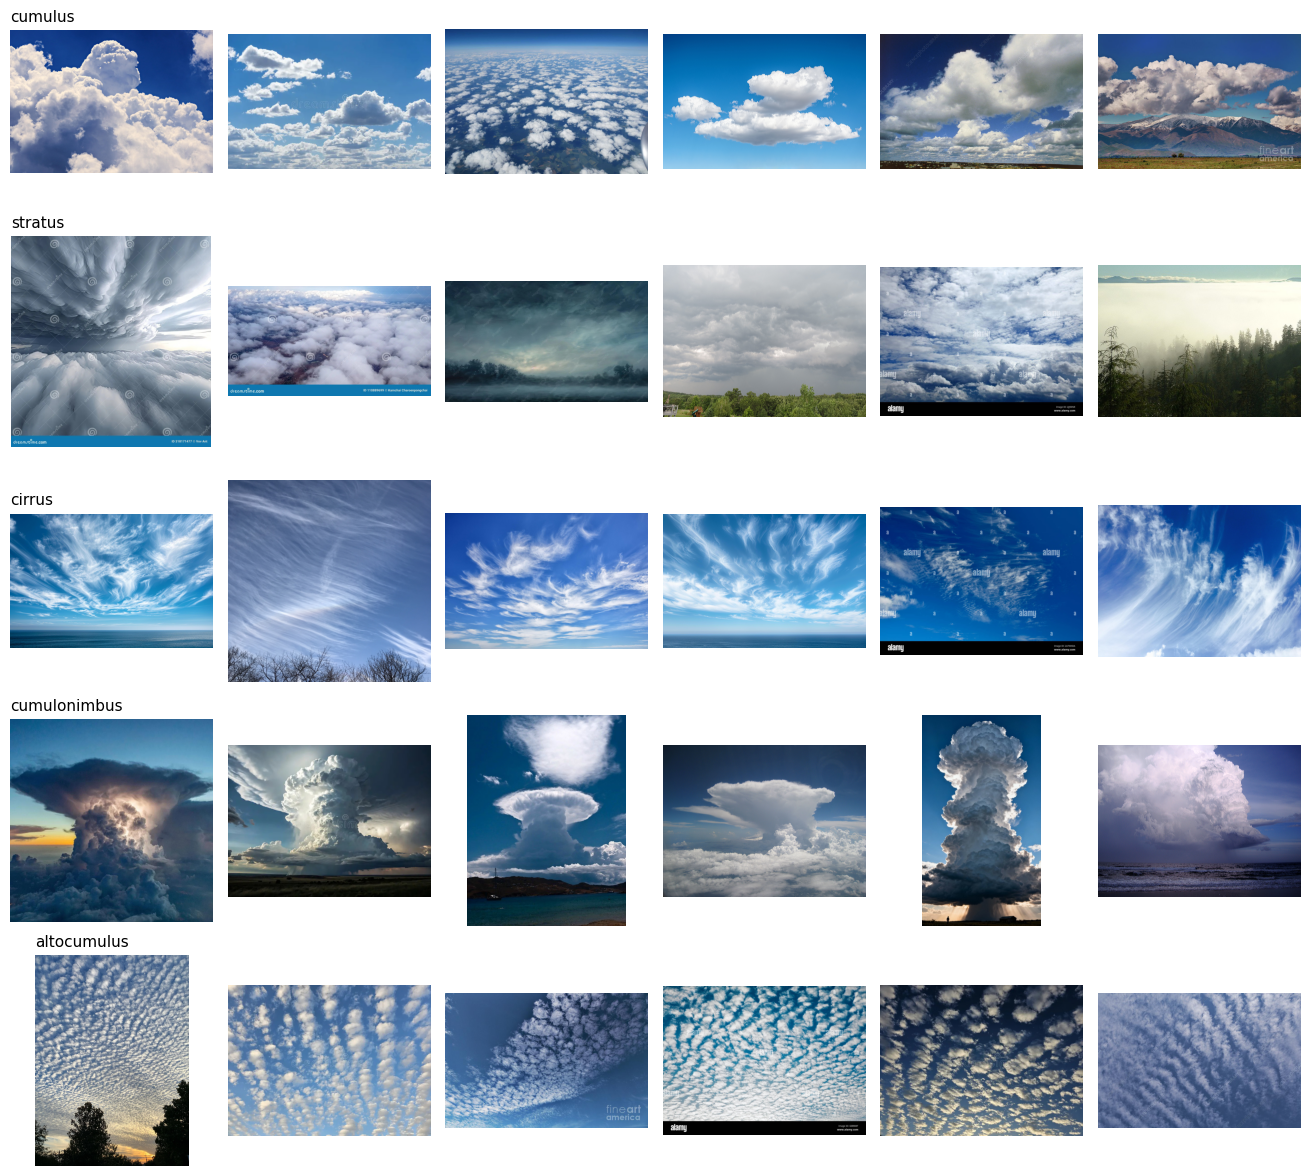

In [14]:
n_show = 6
labels = list(summary['classes'].keys())

fig, axes = plt.subplots(len(labels), n_show, figsize=(2.2 * n_show, 2.4 * len(labels)))
axes = np.atleast_2d(axes)

for r, label in enumerate(labels):
    files = sorted(Path(summary['save_dir'], label).glob('*.jpg'))[:n_show]
    for c in range(n_show):
        ax = axes[r, c]
        ax.axis('off')
        if c < len(files):
            ax.imshow(Image.open(files[c]))
            if c == 0:
                ax.set_title(label, loc='left', fontsize=11)

plt.tight_layout()
plt.show()

**In simple terms: first look**
- Shows the first 6 pictures of each cloud type, one row per class.
- This is a quick check that the searches returned real cloud photos, not drawings, diagrams, or text.
- It is not the full cleaning. Removing wrong pictures and near-duplicates happens in Notebook 2.

## 6. Turning the records into a manifest

`records` is one row per saved image. The manifest is the permanent record of what you trained on,
and it matters more here than in a normal project: **search results change over time, so re-running
this scraper later will not give you the same dataset.** The manifest is the only reproducible
account of the run.

The prompt requires at minimum `filename`, `label`, `source_url`, `query`, and a boolean
`readable`. The scraper supplies everything but `readable`, which comes from the integrity pass in
section 4.1.

Notebook 2 extends this file with a `kept` column. Add to it there; do not overwrite it.

In [15]:
manifest = pd.DataFrame(records)

# readable comes from the integrity pass in 4.1: False for every file it deleted
unreadable_names = [name for label, name, error in unreadable]
manifest['readable'] = ~manifest['filename'].isin(unreadable_names)

Path('data').mkdir(exist_ok=True)
manifest.to_csv('data/P2_manifest.csv', index=False)

print(f'{len(manifest)} rows written to data/P2_manifest.csv')
manifest.head()

2000 rows written to data/P2_manifest.csv


,filename,label,query,image_url,source_url,title,width,height,readable
0,cumulus_0000.jpg,cumulus,cumulus clouds,https://cdn.pixabay.com/photo/2022/05/21/07/22...,https://pixabay.com/photos/cumulus-clouds-clou...,Cumulus Clouds Sky - Free photo on Pixabay,1280,903,True
1,cumulus_0001.jpg,cumulus,fair weather cumulus sky,https://thumbs.dreamstime.com/b/fair-weather-c...,https://www.dreamstime.com/fair-weather-cumulu...,Fair Weather Cumulus Clouds Stock Photo - Imag...,800,534,True
2,cumulus_0002.jpg,cumulus,cumulus humilis clouds,https://cloudatlas.wmo.int/images/compressed/4...,https://fity.club/lists/suggestions/nuvem-humi...,Nuvem Humilis Satellite Imagery Shows Powerful...,2433,1737,True
3,cumulus_0003.jpg,cumulus,cumulus clouds,https://images.pexels.com/photos/4610805/pexel...,https://www.pexels.com/photo/white-cumulus-clo...,White cumulus clouds in blue sky · Free Stock ...,5058,3372,True
4,cumulus_0004.jpg,cumulus,fair weather cumulus sky,https://media.sciencephoto.com/image/e1200372/...,https://www.sciencephoto.com/media/161319/view...,Sky with fair-weather cumulus clouds - Stock I...,800,531,True


**In simple terms: the manifest**
- Saves one row per picture to `data/P2_manifest.csv`, with `filename`, `label`, `query`, `image_url`, `source_url`, `title`, `width`, `height`, and `readable`. That covers all the required columns.
- **Output:** how many rows were written, plus the first 5 rows.
- **Why it matters:** search results change over time, so this file is our only exact record of what we collected. It holds links and labels only, no images.

## Review

This notebook built a small labeled image dataset from scratch:

1. **The scraper** (`ddgs_scraper.py`) searches for images, downloads results, filters by size and
   aspect ratio, and saves one folder per class
2. **Classes and queries** are declared as a dictionary — several queries per class, because one
   query returns one narrow slice of a category
3. **Running it** produced both the images on disk and a record per image
4. **Integrity and accounting** opened every saved file, tracked each class requested →
   downloaded → readable, and flagged any class at risk of ending up short
5. **Looking at the images** is the fastest way to catch a query that returned the wrong thing
6. **The manifest** is the reproducible record of a scrape that cannot be reproduced by re-running

### To turn this into your P2 Notebook 2

- [x] Replace `CLASS_QUERIES` with your own 3–10 classes, and justify each in a markdown cell:
      why these, what makes them separable, where you expect the model to struggle
- [x] State, before you model anything, which **pair of classes you expect to be confused most**.
      Notebook 3 will check you
- [x] Justify every argument you pass to `build_image_dataset`
- [x] Scrape at full scale — aim to save 300–400 per class to land 200 after cleaning
- [x] Re-scrape any class the accounting table flags as at risk — **now**, not after Notebook 2

**Next:** `P2_Images-2_Preprocessing_<TeamName>.ipynb` turns this folder of search results into
an actual dataset.

## TeamKAI summary and handoff to Notebook 2

- **Goal:** build our own labeled cloud photo dataset to train a model that tells cloud types apart.
- **How:** searched Bing for 5 cloud types (3 phrases each), saved up to 400 images per class into a folder outside the repo, opened every file to check it, and counted each class from requested → downloaded → readable.
- **Result:** see the accounting table and the plain-English check in section 4.2 for the final counts and whether any class was at risk.
- **Record:** `data/P2_manifest.csv` lists every image, its label, the query that found it, and where it came from.
- **Limits:** the query-match check only reads text, not pictures, so some wrong clouds (and ground fog) will be in the folders. Duplicates are not removed here. Both are handled in Notebook 2, which adds a `kept` column to the manifest without overwriting it.
- **Prediction to check in Notebook 3:** `cumulus` ↔ `altocumulus` will be the most-confused pair.